In [1]:
%load_ext autoreload
%autoreload 2
import warnings
warnings.filterwarnings('ignore')

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
pd.options.display.max_columns=500
pd.options.display.max_rows=200
pd.options.display.float_format = "{:.3e}".format

In [3]:
path_dados = r"C:\Python - Projects\Aulas WeCogno\Trabalho - Inadimplência\data\raw"

cad = pd.read_parquet(f'{path_dados}/base_cadastral.parquet')
sub = pd.read_parquet(f'{path_dados}/base_submissao.parquet') # por ultimo
hist_emp = pd.read_parquet(f'{path_dados}/historico_emprestimos.parquet')
hist_parc = pd.read_parquet(f'{path_dados}/historico_parcelas.parquet')

In [4]:
cad.head(1) # tem bastante categorica

,id_cliente,sexo,data_nascimento,qtd_filhos,qtd_membros_familia,renda_anual,tipo_renda,ocupacao,tipo_organizacao,nivel_educacao,estado_civil,tipo_moradia,possui_carro,possui_imovel,nota_regiao_cliente,nota_regiao_cliente_cidade
0,100023,Feminino,1994-01-30,1,2.000e+00,"90.000,00",Servidor público,Equipe administrativa,Educação infantil,Ensino superior,Solteiro,Casa ou apartamento,Não,Sim,2,2


In [5]:
sub.head(1) #

,id_cliente,data_solicitacao,dia_semana_solicitacao,hora_solicitacao,tipo_contrato,valor_credito,valor_bem,valor_parcela
0,100023,2025-02-24,segunda-feira,12:28:44,Financiamento de consumo,5.445e+05,4.545e+05,1.756e+04


In [6]:
hist_emp.head(1)

,id_contrato,id_cliente,tipo_contrato,status_contrato,data_decisao,data_liberacao,data_primeiro_vencimento,data_ultimo_vencimento_original,data_ultimo_vencimento,data_encerramento,valor_solicitado,valor_credito,valor_bem,valor_parcela,valor_entrada,percentual_entrada,qtd_parcelas_planejadas,taxa_juros_padrao,taxa_juros_promocional,tipo_pagamento,finalidade_emprestimo,tipo_cliente,faixa_rendimento,tipo_portfolio,tipo_produto,categoria_bem,combinacao_produto,setor_vendedor,canal_venda,area_venda,dia_semana_solicitacao,hora_solicitacao,indicador_ultima_solicitacao_contrato,indicador_ultima_solicitacao_dia,motivo_recusa,acompanhantes_cliente,indicador_seguro_contratado
0,2802425,108129,Empréstimo em dinheiro,Aprovado,2024-08-29,NaN,2024-09-28,2027-08-14,NaN,NaN,6.075e+05,6.797e+05,6.075e+05,2.519e+04,NaN,NaN,3.600e+01,NaN,NaN,Não informado,Não informado,Recorrente,baixa ação,Dinheiro,venda cruzada,Não informado,Dinheiro venda cruzada: low,Não informado,Central de atendimento,-1,quinta-feira,11:05:09,Sim,1,Não se aplica,Desacompanhado,1.000e+00


# Ingestão

## historico_parcelas

In [7]:
hist_parc.head(1)

,id_contrato,id_cliente,versao_parcela,numero_parcela,data_prevista_pagamento,data_real_pagamento,valor_previsto_parcela,valor_pago_parcela
0,1594684,100193,0.000e+00,56,2021-12-21,2021-12-21,3.019e+02,3.019e+02


In [8]:
hist_parc.duplicated().sum()

np.int64(4976)

In [9]:
hist_parc.drop_duplicates()

,id_contrato,id_cliente,versao_parcela,numero_parcela,data_prevista_pagamento,data_real_pagamento,valor_previsto_parcela,valor_pago_parcela
0,1594684,100193,0.000e+00,56,2021-12-21,2021-12-21,3.019e+02,3.019e+02
1,1995642,134723,1.000e+00,38,2021-08-09,2021-08-04,1.295e+04,1.295e+04
2,1720935,176364,1.000e+00,9,2024-03-06,2024-03-04,6.119e+04,6.119e+04
3,1439208,154898,1.000e+00,20,2024-08-11,2024-08-07,8.851e+03,8.851e+03
4,1640082,172575,1.000e+00,4,2022-11-15,2022-11-10,8.720e+03,8.720e+03
...,...,...,...,...,...,...,...,...
1664373,1323172,217502,1.000e+00,2,2022-04-30,2022-07-13,1.145e+04,1.356e+04
1664376,1780171,119721,1.000e+00,7,2020-10-18,2020-09-22,2.563e+03,3.080e+03
1664377,2855181,460177,0.000e+00,4,2023-09-12,2023-09-20,2.422e+03,2.234e+03
1664380,2506179,437996,0.000e+00,55,2020-08-11,2020-08-11,2.250e+03,2.299e+03


In [10]:
hist_parc.info()

<class 'pandas.DataFrame'>
RangeIndex: 1664384 entries, 0 to 1664383
Data columns (total 8 columns):
 #   Column                   Non-Null Count    Dtype  
---  ------                   --------------    -----  
 0   id_contrato              1664384 non-null  int64  
 1   id_cliente               1664384 non-null  int64  
 2   versao_parcela           1664384 non-null  float64
 3   numero_parcela           1664384 non-null  int64  
 4   data_prevista_pagamento  1664384 non-null  str    
 5   data_real_pagamento      1660729 non-null  str    
 6   valor_previsto_parcela   1664384 non-null  float64
 7   valor_pago_parcela       1660732 non-null  float64
dtypes: float64(3), int64(3), str(2)
memory usage: 133.5 MB


### coluna a coluna

#### (int64) id_cliente, id_contrato, numero_parcela e versao_parcela 
    
    - id_cliente e id_contrato -> teoricamente devem >= 0 e de fato já são!
    
    - numero_parcela >= 0 até um valor máximo
    
    - versao_parcela >= 0!

        Além disso: dado uma parcela de um determinado cliente de um determinado contrato, serão mantidos as parcelas mais recentes (maior número)

#### (datetime) data_prevista_pagamento e data_real_pagamento + nova feature: dias_atraso

    - corrigir possíveis datas inválidas (coerce)

    - dias_atraso = data_real_pagamento - data_prevista_pagamento (em dias)

#### (binárias) novas features: t1, t30, t60, t90 

    - As novas features são baseadas em dias atraso. 
    
        Se atraso >= 1 dia, t1 = True, se atraso >= 30 dias, t30 = True, etc

#### (float) valor_previsto_parcela e valor_pago_parcela + novas features: deficit e deficit_perc

    - 

    - 

In [11]:
hist_parc['data_prevista_pagamento'] = pd.to_datetime(hist_parc['data_prevista_pagamento'], format='%Y-%m-%d', errors='coerce')
hist_parc['data_real_pagamento'] = pd.to_datetime(hist_parc['data_real_pagamento'], format='%Y-%m-%d', errors='coerce')
hist_parc['dias_atraso'] = (hist_parc['data_real_pagamento'] - hist_parc['data_prevista_pagamento']).dt.days.astype('Int64')

In [12]:
hist_parc['t90'] = hist_parc.dias_atraso >= 90 # classico para banco
hist_parc['t60'] = hist_parc.dias_atraso >= 60
hist_parc['t30'] = hist_parc.dias_atraso >= 30
hist_parc['t1'] = hist_parc.dias_atraso >= 1 #mais agressivo - 14,07% é muito. Falência

In [13]:
hist_parc[['t90', 't60', 't30', 't1']].sum()/len(hist_parc)*100

t90   2.417e-01
t60   6.501e-01
t30   1.502e+00
t1    1.407e+01
dtype: Float64

In [14]:
# conceito diferente: se pagou tudo antes do final total, tá bom.
hist_parc['deficit'] = hist_parc.valor_previsto_parcela - hist_parc.valor_pago_parcela #positivo significa divida
hist_parc['deficit_perc'] = (hist_parc.deficit / hist_parc.valor_previsto_parcela)*100 #positivo significa divida
hist_parc.head(1)

,id_contrato,id_cliente,versao_parcela,numero_parcela,data_prevista_pagamento,data_real_pagamento,valor_previsto_parcela,valor_pago_parcela,dias_atraso,t90,t60,t30,t1,deficit,deficit_perc
0,1594684,100193,0.000e+00,56,2021-12-21,2021-12-21,3.019e+02,3.019e+02,0,False,False,False,False,0.000e+00,0.000e+00


### Questões levantadas e decisões

#### 1) Versão parcela varia para um mesmo numero_parcela, de um determinado contrato de um cliente. 

Decisão: Manter a parcela mais recente (maior valor)

In [23]:
parc = hist_parc.sort_values(['id_contrato', 'id_cliente', 'numero_parcela', 'data_real_pagamento', 'versao_parcela'])\
    .drop_duplicates(subset=hist_parc.columns.to_list().remove('versao_parcela'), keep='last') # last é a mais atual -> 

In [24]:
parc[['t90', 't60', 't30', 't1']].sum()/len(hist_parc)*100 # taxas de inadimplência por períodos de atraso de pagamento (nas versões mais atuais)

t90   2.409e-01
t60   6.480e-01
t30   1.498e+00
t1    1.403e+01
dtype: Float64

In [46]:
tst_dias_atraso = parc.drop(columns=['t90', 't60', 't30', 't1'])

In [48]:
for i in range(1, 181):
    tst_dias_atraso[f't{i}'] = tst_dias_atraso['dias_atraso'] >= i


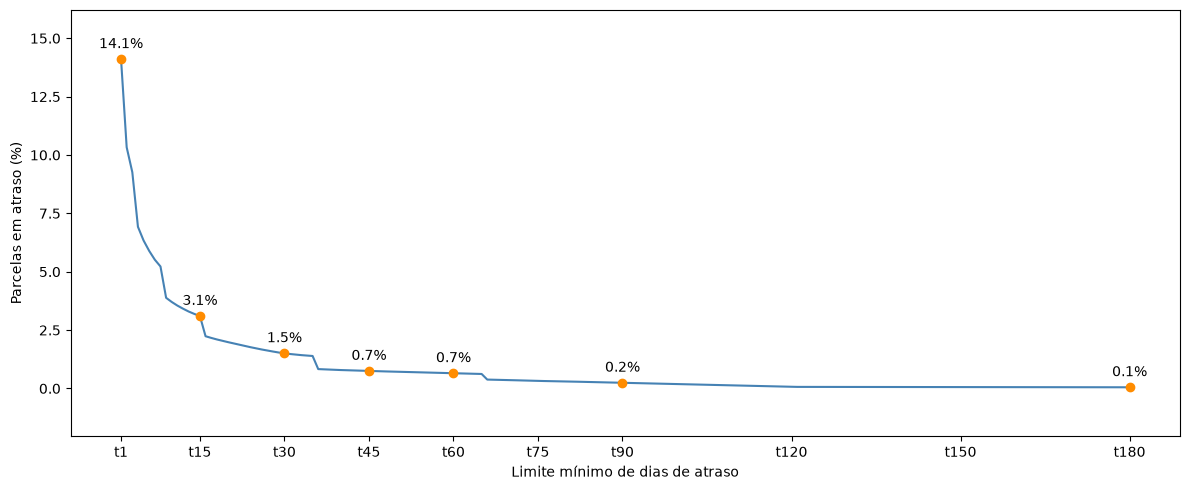

In [68]:

dias = list(range(1, 181))
taxas = tst_dias_atraso[[f"t{dia}" for dia in dias]].mean() * 100
taxas.index = dias

destaques = [1, 15, 30, 45, 60, 90, 180]
mobs = [1, *range(15, 91, 15), *range(120, 181, 30)]

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(dias, taxas, color="steelblue")
ax.scatter(destaques, taxas.loc[destaques], color="darkorange", zorder=3)

for dia in destaques:
    taxa = taxas.loc[dia]
    ax.annotate(
        f"{taxa:.1f}%",
        (dia, taxa),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
    )

ax.set_xticks(mobs, labels=[f"t{dia}" for dia in mobs])
ax.set_xlabel("Limite mínimo de dias de atraso")
ax.set_ylabel("Parcelas em atraso (%)")
ax.margins(y=0.15)
fig.tight_layout()
plt.show()

In [26]:
parc[(parc['id_contrato']==1000013) & (parc['id_cliente']==215520)].sort_values(by=['numero_parcela', 'data_real_pagamento', 'versao_parcela'])

,id_contrato,id_cliente,versao_parcela,numero_parcela,data_prevista_pagamento,data_real_pagamento,valor_previsto_parcela,valor_pago_parcela,dias_atraso,t90,t60,t30,t1,deficit,deficit_perc
445200,1000013,215520,1.000e+00,1,2021-05-23,2021-05-17,1.335e+04,1.335e+04,-6,False,False,False,False,0.000e+00,0.000e+00
546026,1000013,215520,1.000e+00,2,2021-06-22,2021-06-16,1.335e+04,1.335e+04,-6,False,False,False,False,0.000e+00,0.000e+00
424340,1000013,215520,1.000e+00,3,2021-07-22,2021-07-07,1.335e+04,1.335e+04,-15,False,False,False,False,0.000e+00,0.000e+00
630741,1000013,215520,1.000e+00,4,2021-08-21,2021-08-17,1.335e+04,1.335e+04,-4,False,False,False,False,0.000e+00,0.000e+00
421328,1000013,215520,1.000e+00,5,2021-09-20,2021-09-15,1.335e+04,1.335e+04,-5,False,False,False,False,0.000e+00,0.000e+00
764585,1000013,215520,1.000e+00,6,2021-10-20,2021-10-11,1.335e+04,1.335e+04,-9,False,False,False,False,0.000e+00,0.000e+00
732199,1000013,215520,1.000e+00,7,2021-11-19,2021-11-16,1.335e+04,1.335e+04,-3,False,False,False,False,0.000e+00,0.000e+00
683538,1000013,215520,1.000e+00,8,2021-12-19,2021-12-16,1.335e+04,1.335e+04,-3,False,False,False,False,0.000e+00,0.000e+00
607626,1000013,215520,1.000e+00,9,2022-01-18,2022-01-14,1.335e+04,1.335e+04,-4,False,False,False,False,0.000e+00,0.000e+00
603993,1000013,215520,1.000e+00,10,2022-02-17,2022-02-15,1.335e+04,1.335e+04,-2,False,False,False,False,0.000e+00,0.000e+00


#### 2) deficits pequenos -> criar filtro para inadimplência

Para empréstimos onde o deficit entre o previsto e o pagamento for muito pequeno (e positivo, ou seja, faltou dinheiro), não vale a pena considerar todos os casos.

Vamos propor um filtro pequeno para identificar "inadimplências relevantes" de fato (Arbitrário)

   - Deve existir atraso (t1 = True)

      &

   - deficit > 1 (pelo menos 1 real de débito pendente)

        &

   - deficit_perc > 5% (1 real deve representar ao menos 5% do valor total)

In [76]:
# Checando parcelas com deficit pequeno mas com atraso de pagamento -> criar filtro para o que é inadimplência de fato
parc.loc[(parc.deficit>5)&(parc.deficit_perc>0.01)&(parc.t1)].sort_values(by=['deficit', 'deficit_perc'])


,id_contrato,id_cliente,versao_parcela,numero_parcela,data_prevista_pagamento,data_real_pagamento,valor_previsto_parcela,valor_pago_parcela,dias_atraso,t90,t60,t30,t1,deficit,deficit_perc
851282,1435847,323425,1.000e+00,3,2020-11-15,2020-11-17,1.328e+04,1.327e+04,2,False,False,False,True,5.040e+00,3.796e-02
448133,2674487,247631,3.000e+00,6,2023-02-26,2023-03-01,1.239e+04,1.239e+04,3,False,False,False,True,5.040e+00,4.067e-02
962964,1648594,316274,1.000e+00,8,2020-10-07,2020-10-09,8.692e+03,8.687e+03,2,False,False,False,True,5.040e+00,5.798e-02
1263033,2105438,404620,1.000e+00,6,2021-12-04,2021-12-08,7.525e+03,7.520e+03,4,False,False,False,True,5.040e+00,6.698e-02
477941,2241032,293133,1.000e+00,9,2021-07-29,2021-08-02,7.163e+03,7.158e+03,4,False,False,False,True,5.040e+00,7.036e-02
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
523324,2651535,251225,2.000e+00,11,2024-01-04,2024-01-10,5.238e+05,1.655e+03,6,False,False,False,True,5.222e+05,9.968e+01
50211,2002349,124465,2.000e+00,1,2021-05-09,2021-05-27,5.698e+05,9.523e+03,18,False,False,False,True,5.603e+05,9.833e+01
208081,2435896,108011,3.000e+00,13,2023-12-11,2023-12-13,1.015e+06,3.435e+05,2,False,False,False,True,6.716e+05,6.616e+01
499366,1562214,265040,3.000e+00,3,2023-08-04,2023-08-15,7.533e+05,2.774e+04,11,False,False,False,True,7.255e+05,9.632e+01


#### 3) se uma pessoa atrasa alguns dias, mas paga tudo, consideramos como inadimplente?

- Inadimplência: por definição 

In [77]:
# Teste
parc.loc[(parc.deficit>1)&(parc.deficit_perc>1)&(parc.dias_atraso==0)].sort_values('deficit')
grp = parc.groupby(['id_contrato','id_cliente','numero_parcela']).agg(valor_pago_parcela_tot = ('valor_pago_parcela', 'sum'),
                                   valor_prev = ('valor_previsto_parcela', 'first'),
                                   dias_atraso = ('dias_atraso', 'max')).reset_index()
grp['deficit_tot'] = grp.valor_prev - grp.valor_pago_parcela_tot
display(grp[(grp['id_contrato']==1000013) & (grp['id_cliente']==215520)])

,id_contrato,id_cliente,numero_parcela,valor_pago_parcela_tot,valor_prev,dias_atraso,deficit_tot
3,1000013,215520,1,1.335e+04,1.335e+04,-6,0.000e+00
4,1000013,215520,2,1.335e+04,1.335e+04,-6,0.000e+00
5,1000013,215520,3,1.335e+04,1.335e+04,-15,0.000e+00
6,1000013,215520,4,1.335e+04,1.335e+04,-4,0.000e+00
7,1000013,215520,5,1.335e+04,1.335e+04,-5,0.000e+00
8,1000013,215520,6,1.335e+04,1.335e+04,-9,0.000e+00
9,1000013,215520,7,1.335e+04,1.335e+04,-3,0.000e+00
10,1000013,215520,8,1.335e+04,1.335e+04,-3,0.000e+00
11,1000013,215520,9,1.335e+04,1.335e+04,-4,0.000e+00
12,1000013,215520,10,1.335e+04,1.335e+04,-2,0.000e+00


### Resumo de verificações e alterações em historico_parcelas

1) Drop de duplicatas (todas as colunas): aqui duplicatas completamente iguais indicam dois pagamentos iguais registrados -> apagar.

    R: 4976 duplicatas completas removidas -> 1 659 408 linhas não duplicadas completamente 

2) registros de um `id_contrato` pertence a um único cliente?
    R: Sim

3) 

In [50]:
hist_emp.head(1)

,id_contrato,id_cliente,tipo_contrato,status_contrato,data_decisao,data_liberacao,data_primeiro_vencimento,data_ultimo_vencimento_original,data_ultimo_vencimento,data_encerramento,valor_solicitado,valor_credito,valor_bem,valor_parcela,valor_entrada,percentual_entrada,qtd_parcelas_planejadas,taxa_juros_padrao,taxa_juros_promocional,tipo_pagamento,finalidade_emprestimo,tipo_cliente,faixa_rendimento,tipo_portfolio,tipo_produto,categoria_bem,combinacao_produto,setor_vendedor,canal_venda,area_venda,dia_semana_solicitacao,hora_solicitacao,indicador_ultima_solicitacao_contrato,indicador_ultima_solicitacao_dia,motivo_recusa,acompanhantes_cliente,indicador_seguro_contratado
0,2802425,108129,Empréstimo em dinheiro,Aprovado,2024-08-29,NaN,2024-09-28,2027-08-14,NaN,NaN,6.075e+05,6.797e+05,6.075e+05,2.519e+04,NaN,NaN,3.600e+01,NaN,NaN,Não informado,Não informado,Recorrente,baixa ação,Dinheiro,venda cruzada,Não informado,Dinheiro venda cruzada: low,Não informado,Central de atendimento,-1,quinta-feira,11:05:09,Sim,1,Não se aplica,Desacompanhado,1.000e+00


In [35]:
# quantidade de contratos com juros_padrão não nulo
hist_emp["taxa_juros_promocional"].isnull().sum()

np.int64(211233)

In [36]:
parc2 = parc.merge(grp[['id_contrato', 'id_cliente', 'numero_parcela', 'deficit_tot']],
          on=['id_contrato', 'id_cliente', 'numero_parcela'], how='left')

In [37]:
tst = parc2.loc[parc2.id_contrato==1905908].sort_values('numero_parcela')
# tst.groupby(['numero_parcela']).agg(valor_pago_parcela_tot = ('valor_pago_parcela', 'sum'),
#                                    valor_prev = ('valor_previsto_parcela', 'first'),
#                                    dias_atraso = ('dias_atraso', 'max')) #PRICE
tst

,id_contrato,id_cliente,versao_parcela,numero_parcela,data_prevista_pagamento,data_real_pagamento,valor_previsto_parcela,valor_pago_parcela,dias_atraso,t90,t60,t30,t1,deficit,deficit_perc,deficit_tot
699750,1905908,319336,1.000e+00,1,2023-06-07,2023-06-04,9.712e+04,9.712e+04,-3,False,False,False,False,0.000e+00,0.000e+00,0.000e+00
699751,1905908,319336,1.000e+00,2,2023-07-07,2023-07-03,9.712e+04,9.712e+04,-4,False,False,False,False,0.000e+00,0.000e+00,0.000e+00
699752,1905908,319336,1.000e+00,3,2023-08-06,2023-08-05,9.712e+04,9.712e+04,-1,False,False,False,False,0.000e+00,0.000e+00,0.000e+00
699753,1905908,319336,1.000e+00,4,2023-09-05,2023-09-06,9.712e+04,9.712e+04,1,False,False,False,True,0.000e+00,0.000e+00,0.000e+00
699754,1905908,319336,1.000e+00,5,2023-10-05,2023-10-04,9.712e+04,9.712e+04,-1,False,False,False,False,0.000e+00,0.000e+00,0.000e+00
699755,1905908,319336,1.000e+00,6,2023-11-04,2023-11-04,9.712e+04,9.712e+04,0,False,False,False,False,0.000e+00,0.000e+00,0.000e+00
699756,1905908,319336,1.000e+00,7,2023-12-04,2023-12-03,9.712e+04,1.378e+03,-1,False,False,False,False,9.574e+04,9.858e+01,0.000e+00
699757,1905908,319336,1.000e+00,7,2023-12-04,2023-12-07,9.712e+04,9.574e+04,3,False,False,False,True,1.378e+03,1.419e+00,0.000e+00
699758,1905908,319336,1.000e+00,8,2024-01-03,2024-01-03,9.712e+04,1.987e+03,0,False,False,False,False,9.513e+04,9.795e+01,0.000e+00
699759,1905908,319336,1.000e+00,8,2024-01-03,2024-01-05,9.712e+04,9.513e+04,2,False,False,False,True,1.987e+03,2.046e+00,0.000e+00


In [38]:
c1 = (parc2.t1)&(parc2.deficit_tot>1) #se atrasou qualquer numero de dias E não pagou o valor total previsto
c2 = parc2.t30 #atrasou mais do que 30 dias - trocar para 90
parc2['target'] = (c1|c2)
target_contrato = parc2.groupby(['id_contrato', 'id_cliente'], as_index=False).agg(target=('target', 'max'))

In [39]:
parc2.head(2)

,id_contrato,id_cliente,versao_parcela,numero_parcela,data_prevista_pagamento,data_real_pagamento,valor_previsto_parcela,valor_pago_parcela,dias_atraso,t90,t60,t30,t1,deficit,deficit_perc,deficit_tot,target
0,1000003,252457,1.000e+00,1,2024-11-19,2024-11-05,4.951e+03,4.951e+03,-14,False,False,False,False,0.000e+00,0.000e+00,0.000e+00,False
1,1000003,252457,1.000e+00,2,2024-12-19,2024-12-02,4.951e+03,4.951e+03,-17,False,False,False,False,0.000e+00,0.000e+00,0.000e+00,False


In [ ]:
cad.head(1) # Falta dado de timestamp|versão|data referencia
feats_cad = [i for i in cad.drop(columns=['sexo', 'id_cliente'])] # transformas data nascimento em idade

In [ ]:
# valor_solicitado
# valor_credito
# valor_bem
# valor_parcela
# tipo_contrato
# dia_semana_solicitacao
feats_emp = ['valor_solicitado', 'valor_credito', 'valor_bem', 'valor_parcela',
            'tipo_contrato', 'dia_semana_solicitacao']
hist_emp['proxy_data_solicitacao'] = hist_emp.data_decisao.fillna(hist_emp.data_liberacao).fillna(hist_emp.data_primeiro_vencimento)
df_emp = hist_emp[['id_cliente', 'id_contrato', 'proxy_data_solicitacao'] + feats_emp].copy()
df_emp['valor_bem'] = df_emp.valor_bem.fillna(df_emp.valor_solicitado)
feats_emp = ['valor_credito', 'valor_bem', 'valor_parcela',
            'tipo_contrato', 'dia_semana_solicitacao']
df_emp.head(1)

,id_cliente,id_contrato,proxy_data_solicitacao,valor_solicitado,valor_credito,valor_bem,valor_parcela,tipo_contrato,dia_semana_solicitacao
0,108129,2802425,2024-08-29,607500.0,679671.0,607500.0,25188.615,Empréstimo em dinheiro,quinta-feira


In [ ]:
# target_contrato, cad feats_cad, df_emp feats_emp
list_colunas = ['id_cliente'] + feats_cad
dftr = cad[list_colunas].copy()
dftr = dftr.merge(df_emp[['id_cliente', 'id_contrato', 'proxy_data_solicitacao'] + feats_emp], on='id_cliente', how='left')
dftr = dftr.loc[dftr.id_contrato.notnull()]
dftr = dftr.merge(target_contrato, on=['id_cliente', 'id_contrato'], how='left')

dftr['idade_solicitacao'] = (pd.to_datetime(dftr.proxy_data_solicitacao, format='%Y-%m-%d')
                            - pd.to_datetime(dftr.data_nascimento.replace('31/02/1990', '1990-03-01'), format='%Y-%m-%d')).dt.days/365
idade_bins = [-np.inf, 18, 25, 35, 45, 55, 65, 75, 95, np.inf]
labels = [f'{idade_bins[i]} - {idade_bins[i+1]}' for i in range(len(idade_bins)-1)]
dftr['idade_solicitacao_cat'] = pd.cut(dftr.idade_solicitacao, bins=idade_bins, labels=labels)
dftr.loc[dftr.qtd_membros_familia<1, 'qtd_membros_familia'] = 1
dftr['qtd_membros_familia'] = dftr.qtd_membros_familia.fillna(1)

def fix_renda(txt):
    rgx = '[\d,]'
    res = ''.join(re.findall(rgx, txt)).replace(',', '.')
    if res == '':
        return '0'
    return res

dftr['renda_anual'] = dftr.renda_anual.apply(lambda x: fix_renda(x)).astype(float)
dftr['renda_por_membro'] = dftr.renda_anual/dftr.qtd_membros_familia

dftr[['nota_regiao_cliente', 'nota_regiao_cliente_cidade']] = dftr[['nota_regiao_cliente', 'nota_regiao_cliente_cidade']].astype(str)

feats_eng = ['idade_solicitacao_cat', 'renda_por_membro'] # numero de inadimplencias anteriores por cliente
# labels

## Teste

In [ ]:
# OVER30 MOB3 por contrato: saldo vencido ha mais de 30 dias no MOB3.
chave_mob3 = ["id_contrato", "id_cliente"]
chave_parcela = chave_mob3 + ["numero_parcela"]
# Ajuste conforme a data ate a qual o historico esta completo.
data_corte_mob3 = pd.Timestamp("2025-01-31")

contratos_mob3 = hist_emp[chave_mob3].copy()
liberacao = pd.to_datetime(hist_emp["data_liberacao"])
decisao = pd.to_datetime(hist_emp["data_decisao"])
contratos_mob3["usa_proxy_concessao"] = liberacao.isna() & decisao.notna()
contratos_mob3["data_mob3"] = liberacao.fillna(decisao) + pd.DateOffset(months=3)
elegiveis_mob3 = contratos_mob3.loc[contratos_mob3["data_mob3"].le(data_corte_mob3)]

campos = chave_parcela + [
    "data_prevista_pagamento", "data_real_pagamento",
    "valor_previsto_parcela", "valor_pago_parcela",
]
mov = hist_parc[campos].merge(
    elegiveis_mob3[chave_mob3 + ["data_mob3"]], on=chave_mob3, validate="many_to_one"
)
mov["dias_no_mob3"] = (mov["data_mob3"] - mov["data_prevista_pagamento"]).dt.days
data_pagamento = mov["data_real_pagamento"]
valor_pago = mov["valor_pago_parcela"]
pago_no_prazo_observado = data_pagamento.le(mov["data_mob3"])
mov["pagamento_incerto"] = (
    (data_pagamento.isna() & valor_pago.gt(0))
    | (pago_no_prazo_observado & valor_pago.isna())
)

parcelas_mob3 = mov.groupby(chave_parcela).agg(
    atraso_min=("dias_no_mob3", "min"),
    atraso_max=("dias_no_mob3", "max"),
    previsto_min=("valor_previsto_parcela", "min"),
    previsto_max=("valor_previsto_parcela", "max"),
    pagamento_incerto=("pagamento_incerto", "any"),
)

# Compare dois cenarios para valores distintos na mesma data:
# considerar apenas o maior valor ou somar todos os valores distintos.
chave_pagamento = chave_parcela + ["data_real_pagamento"]
pagos = mov.loc[
    pago_no_prazo_observado & valor_pago.notna(),
    chave_pagamento + ["valor_pago_parcela"],
].drop_duplicates()
pagos_por_dia = pagos.groupby(chave_pagamento)["valor_pago_parcela"].agg(
    pago_min="max", pago_max="sum"
)
parcelas_mob3 = parcelas_mob3.join(pagos_por_dia.groupby(level=chave_parcela).sum())
saldo_min = parcelas_mob3["previsto_min"] - parcelas_mob3["pago_max"].fillna(0)
saldo_max = parcelas_mob3["previsto_max"] - parcelas_mob3["pago_min"].fillna(0)

em_atraso = (
    parcelas_mob3["atraso_min"].gt(30)
    & saldo_min.gt(0.01)
    & ~parcelas_mob3["pagamento_incerto"]
)
sem_atraso = parcelas_mob3["atraso_max"].le(30) | saldo_max.le(0.01)
por_contrato = (
    parcelas_mob3.assign(em_atraso=em_atraso, sem_atraso=sem_atraso)
    .groupby(level=chave_mob3)
    .agg(alguma_em_atraso=("em_atraso", "any"), todas_sem_atraso=("sem_atraso", "all"))
)
por_contrato["over30_mob3"] = (
    por_contrato["alguma_em_atraso"].astype("boolean")
    .mask(~(por_contrato["alguma_em_atraso"] | por_contrato["todas_sem_atraso"]))
)
contratos_mob3 = contratos_mob3.join(por_contrato["over30_mob3"], on=chave_mob3)
taxa_over30_mob3 = contratos_mob3["over30_mob3"].mean() * 100

resumo_mob3 = pd.Series({
    "Contratos com MOB3 ate o corte": len(elegiveis_mob3),
    "Contratos com alvo calculavel": contratos_mob3["over30_mob3"].count(),
    "Contratos OVER30 MOB3": contratos_mob3["over30_mob3"].sum(),
    "OVER30 MOB3 (%)": taxa_over30_mob3,
})
resumo_mob3

## Treino

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, roc_auc_score, accuracy_score, precision_score, recall_score
import seaborn as sns

from lightgbm import LGBMClassifier
from xgboost import XGBClassifier

In [ ]:
df = dftr.copy()
target = 'target'
FREQ_ENC_MINIMUM_UNIQUE = 5

In [ ]:
X = df[feats_cad + feats_emp + feats_eng].drop('data_nascimento', axis=1)
y = df[target].astype('boolean').fillna(False).astype('int8')
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [ ]:
# Identify feature types
num_features = X.select_dtypes(include=np.number).columns.tolist()
cat_features = X.select_dtypes(exclude=np.number).columns.tolist()
cat_freq_features = np.array(cat_features)[X_train[cat_features].nunique() > FREQ_ENC_MINIMUM_UNIQUE]
cat_freq_features = [str(i) for i in cat_freq_features]
cat_dummy_features = [i for i in cat_features if i not in cat_freq_features]

# Se > conf (FREQ_ENC_MINIMUM_UNIQUE) valores unicos, Fencoding, do contrário, onehot.
class FrequencyEncoder(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.feature_names_in_ = np.array(X.columns, dtype=object)
        self.freq_maps_ = {}
        for col in X.columns:
            self.freq_maps_[col] = (
                X[col].value_counts(normalize=True).to_dict()
            )
        return self

    def transform(self, X):
        X = pd.DataFrame(
            X,
            columns=self.feature_names_in_
        ).copy()
        for col in X.columns:
            X[col] = X[col].map(
                self.freq_maps_[col]
            ).fillna(0)
        return X.to_numpy()

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            input_features = self.feature_names_in_
        return np.asarray(input_features, dtype=object)



num_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

cat_freq_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", FrequencyEncoder())
])

cat_dummy_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder())
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_features),
    ("cat_freq", cat_freq_pipeline, cat_freq_features),
    ("cat_dummy", cat_dummy_pipeline, cat_dummy_features)
])

In [ ]:
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=-1,
        num_leaves=31,
        random_state=42,
        verbosity=-1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        n_jobs=-1
    ),

    # "Logistic": LogisticRegression(
    # )
}


In [ ]:
results = {}
fitted_models = {}
feature_names = None

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    results[name] = {
        "f1": f1_score(y_test, predictions),
        "roc_auc": roc_auc_score(y_test, predictions),
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(y_test, predictions),
        "recall": recall_score(y_test, predictions)
    }

    fitted_models[name] = pipeline

    if feature_names is None:
        feature_names = (
            pipeline.named_steps["preprocessor"]
            .get_feature_names_out()
        )

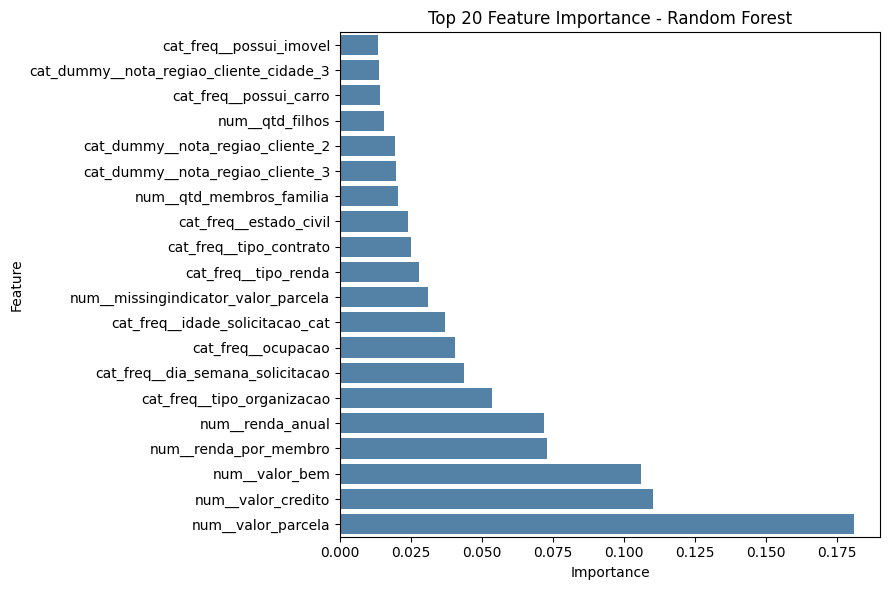

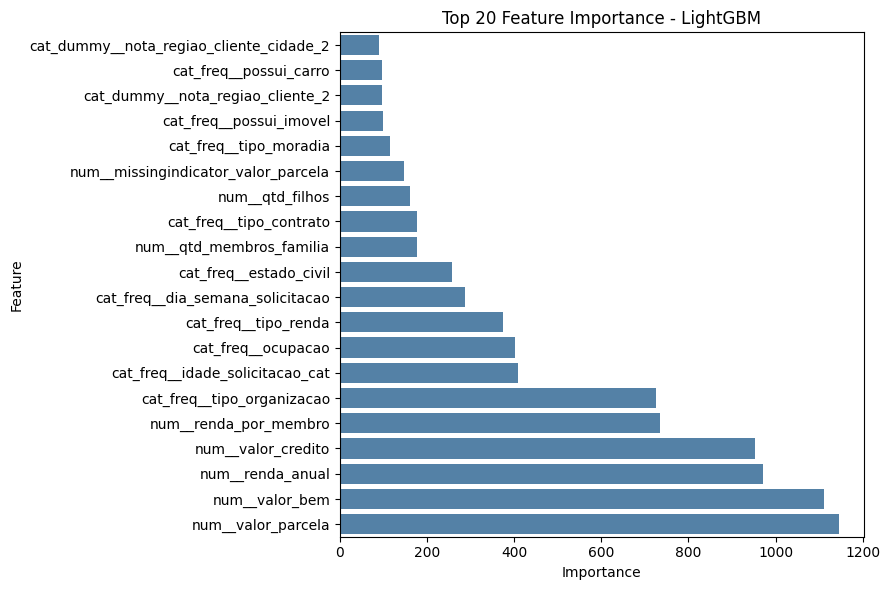

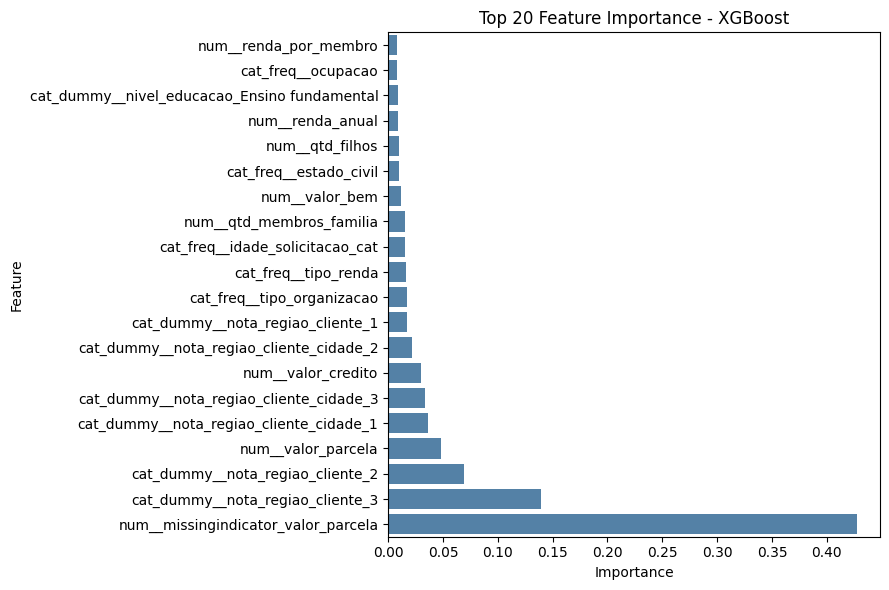

In [ ]:
def get_feature_importance(pipeline, feature_names):

    model = pipeline.named_steps["model"]
    if hasattr(model, "feature_importances_"):
        importance = model.feature_importances_
    elif hasattr(model, "coef_"):
        importance = np.abs(model.coef_)
    else:
        raise ValueError("Model does not provide feature importance.")
    return pd.Series(
        importance,
        index=feature_names
    ).sort_values(ascending=False)

# Plot importance for each model

for name, pipeline in fitted_models.items():
    importance = get_feature_importance(
        pipeline,
        feature_names
    ).head(20).sort_values()
    plt.figure(figsize=(9, 6))
    sns.barplot(
        x=importance.values,
        y=importance.index,
        color="steelblue"
    )

    plt.title(f"Top 20 Feature Importance - {name}")
    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()


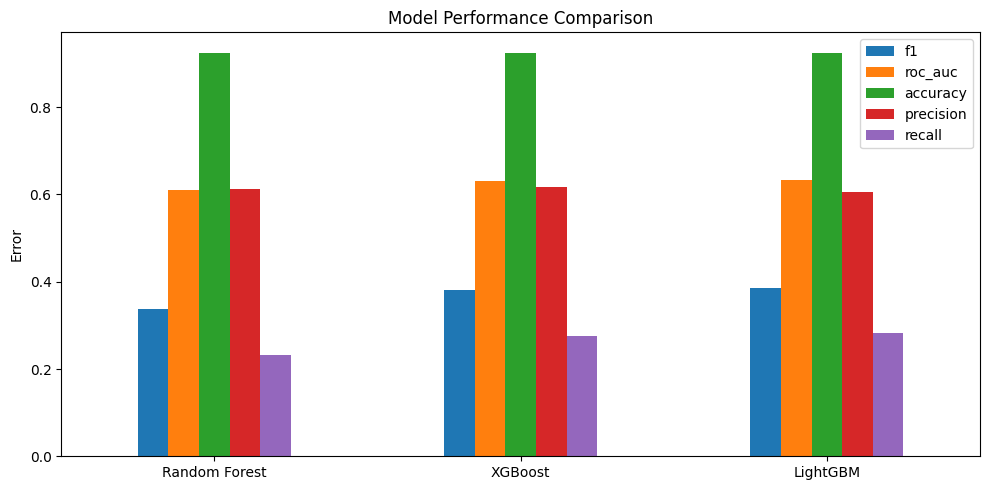

<Axes: >

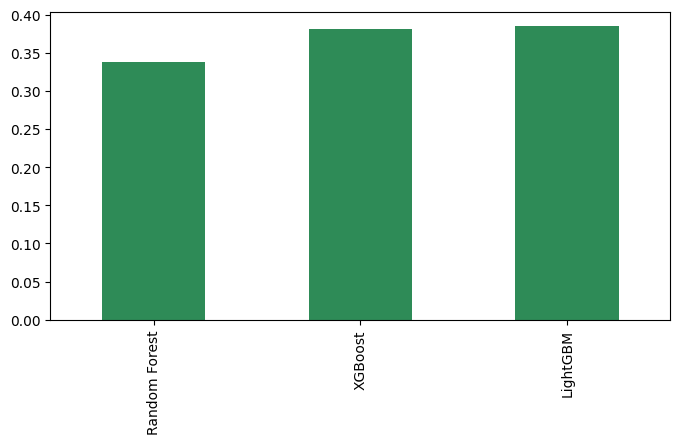

In [ ]:
# ============================================================
# 7. MODEL COMPARISON
# ============================================================

results_df.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Error")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

results_df["f1"].plot(
    kind="bar",
    figsize=(8, 4),
    color="seagreen"
)

In [ ]:
import optuna

MODEL_NAME = "lightgbm"  # "randomforest" or "lightgbm"

N_TRIALS = 10
CV_FOLDS = 5
RANDOM_STATE = 32


# ============================================================
# 2. OPTUNA OBJECTIVE
# ============================================================

def objective(trial):

    if MODEL_NAME == "randomforest":
        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators", 200, 1000, step=100
            ),
            max_depth=trial.suggest_int(
                "max_depth", 3, 30
            ),
            min_samples_split=trial.suggest_int(
                "min_samples_split", 2, 20
            ),
            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf", 1, 10
            ),
            max_features=trial.suggest_categorical(
                "max_features", ["sqrt", "log2", 1.0]
            ),
            random_state=RANDOM_STATE,
            n_jobs=-1
        )

    elif MODEL_NAME == "lightgbm":

        model = LGBMClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators", 200, 1500, step=100
            ),
            learning_rate=trial.suggest_float(
                "learning_rate", 0.005, 0.15, log=True
            ),
            num_leaves=trial.suggest_int(
                "num_leaves", 10, 100
            ),
            max_depth=trial.suggest_int(
                "max_depth", 3, 15
            ),
            min_child_samples=trial.suggest_int(
                "min_child_samples", 5, 50
            ),
            subsample=trial.suggest_float(
                "subsample", 0.6, 1.0
            ),
            colsample_bytree=trial.suggest_float(
                "colsample_bytree", 0.6, 1.0
            ),
            reg_alpha=trial.suggest_float(
                "reg_alpha", 1e-4, 10.0, log=True
            ),
            reg_lambda=trial.suggest_float(
                "reg_lambda", 1e-4, 10.0, log=True
            ),
            random_state=RANDOM_STATE,
            verbosity=-1,
            n_jobs=-1
        )

    else:
        raise ValueError("Unsupported model")

    # Full pipeline
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    # Cross-validation
    cv = KFold(
        n_splits=CV_FOLDS,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="f1",
        n_jobs=1
    )

    return -scores.mean()


# ============================================================
# 3. OPTIMIZATION
# ============================================================

study = optuna.create_study(
    direction="minimize",
    study_name=f"{MODEL_NAME}_optimization"
)

study.optimize(
    objective,
    n_trials=N_TRIALS,
    show_progress_bar=True
)

[I 2026-11-22 18:07:46,056] A new study created in memory with name: lightgbm_optimization


  0%|          | 0/10 [00:00<?, ?it/s]

[I 2026-11-22 18:07:54,693] Trial 0 finished with value: -0.3600676484057333 and parameters: {'n_estimators': 200, 'learning_rate': 0.14413198475343855, 'num_leaves': 73, 'max_depth': 4, 'min_child_samples': 48, 'subsample': 0.8539565370240245, 'colsample_bytree': 0.7609844375255574, 'reg_alpha': 0.0005313513018384012, 'reg_lambda': 0.012627710308796383}. Best is trial 0 with value: -0.3600676484057333.
[I 2026-11-22 18:08:43,433] Trial 1 finished with value: -0.3813393808637427 and parameters: {'n_estimators': 900, 'learning_rate': 0.1440532196463823, 'num_leaves': 31, 'max_depth': 12, 'min_child_samples': 12, 'subsample': 0.6370143207484867, 'colsample_bytree': 0.7935821010802382, 'reg_alpha': 0.02122489197509044, 'reg_lambda': 0.026255128114845632}. Best is trial 1 with value: -0.3813393808637427.
[I 2026-11-22 18:09:16,309] Trial 2 finished with value: -0.3865509944061012 and parameters: {'n_estimators': 400, 'learning_rate': 0.04541004110132533, 'num_leaves': 54, 'max_depth': 8, '

In [ ]:
import optuna

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier


MODEL_NAME = "lightgbm"  # "randomforest" or "lightgbm"

N_TRIALS = 3
CV_FOLDS = 5
RANDOM_STATE = 32

def objective(trial):

    if MODEL_NAME == "randomforest":

        model = RandomForestClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators", 200, 1000, step=100
            ),
            max_depth=trial.suggest_int(
                "max_depth", 3, 30
            ),
            min_samples_split=trial.suggest_int(
                "min_samples_split", 2, 20
            ),
            min_samples_leaf=trial.suggest_int(
                "min_samples_leaf", 1, 10
            ),
            max_features=trial.suggest_categorical(
                "max_features", ["sqrt", "log2", 1.0]
            ),
            random_state=RANDOM_STATE,
            n_jobs=-1
        )

    elif MODEL_NAME == "lightgbm":

        model = LGBMClassifier(
            n_estimators=trial.suggest_int(
                "n_estimators", 200, 1500, step=100
            ),
            learning_rate=trial.suggest_float(
                "learning_rate", 0.005, 0.15, log=True
            ),
            num_leaves=trial.suggest_int(
                "num_leaves", 10, 100
            ),
            max_depth=trial.suggest_int(
                "max_depth", 3, 15
            ),
            min_child_samples=trial.suggest_int(
                "min_child_samples", 5, 50
            ),
            subsample=trial.suggest_float(
                "subsample", 0.6, 1.0
            ),
            colsample_bytree=trial.suggest_float(
                "colsample_bytree", 0.6, 1.0
            ),
            reg_alpha=trial.suggest_float(
                "reg_alpha", 1e-4, 10.0, log=True
            ),
            reg_lambda=trial.suggest_float(
                "reg_lambda", 1e-4, 10.0, log=True
            ),
            random_state=RANDOM_STATE,
            verbosity=-1,
            n_jobs=-1
        )

    else:
        raise ValueError("Unsupported model")
    pipeline = ImbPipeline([
        ("preprocessor", preprocessor),
        ("smote", SMOTE(
            random_state=RANDOM_STATE,
            k_neighbors=5
        )),
        ("model", model)
    ])
    cv = StratifiedKFold(
        n_splits=CV_FOLDS,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="f1",
        n_jobs=1
    )

    return -scores.mean()

study = optuna.create_study(
    direction="minimize",
    study_name=f"{MODEL_NAME}_optimization"
)
study.optimize(
    objective,
    n_trials=N_TRIALS,
    show_progress_bar=True
)


print("Best F1-score:", -study.best_value)
print("Best parameters:", study.best_params)


[I 2026-11-22 18:37:02,781] A new study created in memory with name: lightgbm_optimization


  0%|          | 0/3 [00:00<?, ?it/s]

[W 2026-11-22 18:37:03,050] Trial 0 failed with parameters: {'n_estimators': 1100, 'learning_rate': 0.10295072699595681, 'num_leaves': 25, 'max_depth': 3, 'min_child_samples': 12, 'subsample': 0.6171081073800376, 'colsample_bytree': 0.933073531176205, 'reg_alpha': 4.224073602631322, 'reg_lambda': 0.02149239075877278} because of the following error: ValueError('\nAll the 5 fits failed.\nIt is very likely that your model is misconfigured.\nYou can try to debug the error by setting error_score=\'raise\'.\n\nBelow are more details about the failures:\n--------------------------------------------------------------------------------\n3 fits failed with the following error:\nTraceback (most recent call last):\n  File "/home/joao/venvst/lib/python3.12/site-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score\n    estimator.fit(X_train, y_train, **fit_params)\n  File "/home/joao/venvst/lib/python3.12/site-packages/sklearn/base.py", line 1389, in wrapper\n    return fit_

ValueError: 
All the 5 fits failed.
It is very likely that your model is misconfigured.
You can try to debug the error by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
3 fits failed with the following error:
Traceback (most recent call last):
  File "/home/joao/venvst/lib/python3.12/site-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "/home/joao/venvst/lib/python3.12/site-packages/sklearn/base.py", line 1389, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/joao/venvst/lib/python3.12/site-packages/imblearn/pipeline.py", line 514, in fit
    Xt, yt = self._fit(X, y, routed_params, raw_params=params)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/joao/venvst/lib/python3.12/site-packages/imbl

Best CV f1: -0.3883324652187423
Best parameters: {'n_estimators': 700, 'learning_rate': 0.04581321933759033, 'num_leaves': 85, 'max_depth': 14, 'min_child_samples': 6, 'subsample': 0.8626537271218433, 'colsample_bytree': 0.8119380978076145, 'reg_alpha': 0.026818927637299244, 'reg_lambda': 0.0068340595158395065}

Test performance:
f1: 0.4012055000941797


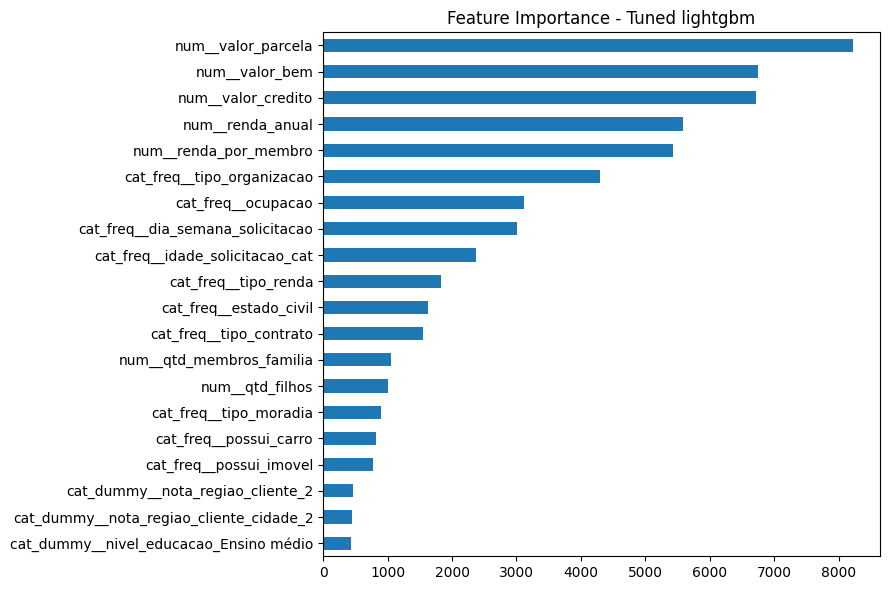

In [ ]:
print("Best CV f1:", study.best_value)
print("Best parameters:", study.best_params)


# ============================================================
# 4. FIT BEST MODEL
# ============================================================

if MODEL_NAME == "randomforest":

    best_model = RandomForestClassifier(
        **study.best_params,
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

elif MODEL_NAME == "lightgbm":

    best_model = LGBMClassifier(
        **study.best_params,
        random_state=RANDOM_STATE,
        verbosity=-1,
        n_jobs=-1
    )


best_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", best_model)
])

best_pipeline.fit(X_train, y_train)


# ============================================================
# 5. TEST EVALUATION
# ============================================================

predictions = best_pipeline.predict(X_test)

print("\nTest performance:")
print("f1:", f1_score(y_test.fillna(False), predictions))


# ============================================================
# 6. FEATURE IMPORTANCE
# ============================================================

feature_names = (
    best_pipeline.named_steps["preprocessor"]
    .get_feature_names_out()
)

model = best_pipeline.named_steps["model"]

importance = pd.Series(
    model.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

importance.head(20).sort_values().plot(
    kind="barh",
    figsize=(9, 6),
    title=f"Feature Importance - Tuned {MODEL_NAME}"
)

plt.tight_layout()
plt.show()

In [ ]:
def get_original_feature_name(preprocessor, transformed_name):
    transformer_name, feature_name = transformed_name.split("__", 1)
    transformers = {
        name: (transformer, columns)
        for name, transformer, columns in preprocessor.transformers_
    }
    transformer, columns = transformers[transformer_name]
    if transformer_name == "num":
        if feature_name.startswith("missingindicator_"):
            return feature_name.replace("missingindicator_", "", 1)
        return feature_name
    if transformer_name == "cat_dummy":
        encoder = transformer.named_steps["encoder"]
        encoded_names = encoder.get_feature_names_out(columns)
        for col, encoded in zip(
            [col for col in columns for _ in encoder.categories_[list(columns).index(col)]],
            encoded_names
        ):
            if encoded == feature_name:
                return col
        raise ValueError(f"Feature not found: {transformed_name}")
    if transformer_name == "cat_freq":
        return feature_name
    return feature_name
    
get_original_feature_name(pipeline['preprocessor'], 'num__valor_parcela')

'valor_parcela'

In [ ]:
n_feats = [29, 20, 15, 10, 5]
results = {}
params = {'n_estimators': 700, 'learning_rate': 0.04581321933759033, 'num_leaves': 85, 
          'max_depth': 14, 'min_child_samples': 6, 'subsample': 0.8626537271218433, 'colsample_bytree': 0.8119380978076145,
          'reg_alpha': 0.026818927637299244, 'reg_lambda': 0.0068340595158395065}

model = LGBMClassifier(
        **params,
        random_state=32,
        verbosity=-1,
        n_jobs=-1
    )
feat_names_proc = [i for i in importance.index]

for n in n_feats:

    _feats = feat_names_proc[:n]
    _feats = list(set([get_original_feature_name(best_pipeline['preprocessor'], i) for i in _feats]))
    
    num_pipeline = Pipeline([
        ("imputer", SimpleImputer(
            strategy="median",
            add_indicator=True
        )),
        ("scaler", StandardScaler())
    ])
    cat_freq_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", FrequencyEncoder())
    ])
    cat_dummy_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder())
    ])
    preprocessor = ColumnTransformer([
        ("num", num_pipeline, [i for i in num_features if i in _feats]),
        ("cat_freq", cat_freq_pipeline, [i for i in cat_freq_features if i in _feats]),
        ("cat_dummy", cat_dummy_pipeline, [i for i in cat_dummy_features if i in _feats])
    ])
    _pipeline = ImbPipeline([
        ("preprocessor", preprocessor),
        ("smote", SMOTE(
            random_state=32,
            k_neighbors=5
        )),
        ("model", model)
    ])
    cv = StratifiedKFold(
        n_splits=CV_FOLDS,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    _pipeline.fit(X_train[_feats], y_train)
    predictions = _pipeline.predict(X_test[_feats])
    results[f'{n}_feats'] = {
        "f1": f1_score(y_test, predictions),
        "roc_auc": roc_auc_score(y_test, predictions),
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(y_test, predictions),
        "recall": recall_score(y_test, predictions)
    }
    fitted_models[f'{n}_feats'] = _pipeline
    if feature_names is None:
        feature_names = (
            pipeline.named_steps["preprocessor"]
            .get_feature_names_out()
        )

In [ ]:
results_df = pd.DataFrame(results).T.sort_values("f1", ascending=False)

print("\nModel performance:")
print(results_df.round(4))


Model performance:
              f1  roc_auc  accuracy  precision  recall
5_feats   0.4346   0.7203    0.8870     0.3732  0.5202
10_feats  0.4194   0.6510    0.9258     0.6043  0.3211
29_feats  0.4029   0.6416    0.9256     0.6102  0.3008
20_feats  0.4029   0.6416    0.9256     0.6102  0.3008
15_feats  0.3998   0.6390    0.9263     0.6242  0.2941


In [ ]:
feat_names_proc[:5]

['num__valor_parcela',
 'num__valor_bem',
 'num__valor_credito',
 'num__renda_anual',
 'num__renda_por_membro']